In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sales = pd.read_csv("../data/processed/sales_cleaned.csv")

sales['Date'] = pd.to_datetime(sales['Date'])

print("Dataset:", sales.shape)

Dataset: (421570, 21)


In [2]:
weekly_sales = (
    sales.groupby('Date')['Weekly_Sales']
    .sum()
    .reset_index()
    .sort_values('Date')
)

weekly_sales.columns = ['Date', 'Sales']

print(weekly_sales.shape)
weekly_sales.head()

(143, 2)


,Date,Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30


In [3]:
weekly_sales.describe()

,Date,Sales
count,143,1.430000e+02
mean,2011-06-17 00:00:00,4.711342e+07
min,2010-02-05 00:00:00,3.959985e+07
25%,2010-10-11 12:00:00,4.488059e+07
50%,2011-06-17 00:00:00,4.624390e+07
75%,2012-02-20 12:00:00,4.779202e+07
max,2012-10-26 00:00:00,8.093142e+07
std,NaN,5.444206e+06


In [4]:
print("Highest sales week:")
print(
    weekly_sales.loc[
        weekly_sales['Sales'].idxmax()
    ]
)

print("\nLowest sales week:")
print(
    weekly_sales.loc[
        weekly_sales['Sales'].idxmin()
    ]
)

Highest sales week:
Date     2010-12-24 00:00:00
Sales             80931415.6
Name: 46, dtype: object

Lowest sales week:
Date     2011-01-28 00:00:00
Sales            39599852.99
Name: 51, dtype: object


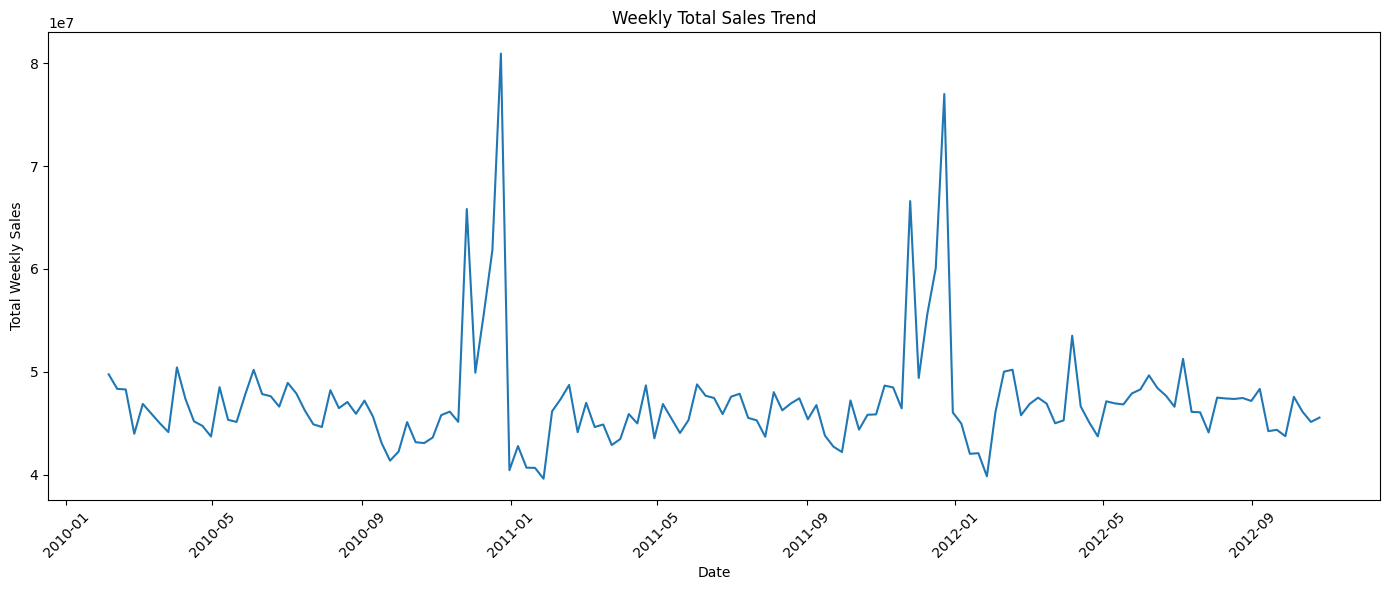

In [5]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales['Date'],
    weekly_sales['Sales']
)

plt.title('Weekly Total Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

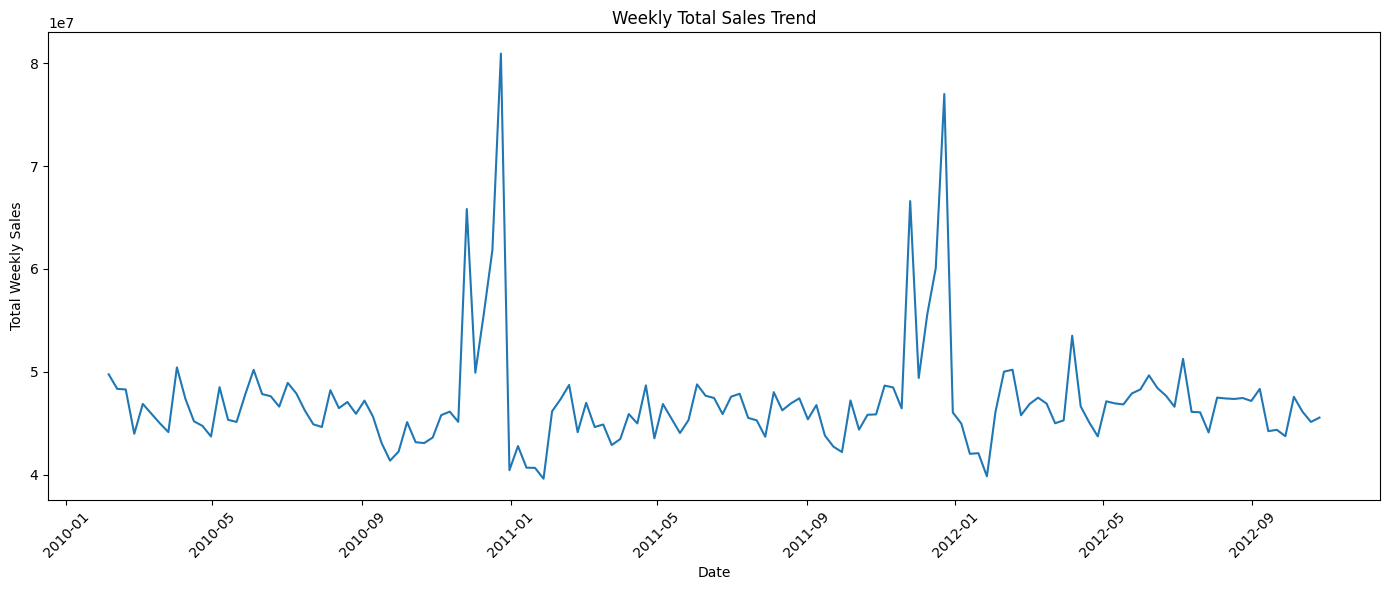

In [6]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales['Date'],
    weekly_sales['Sales']
)

plt.title('Weekly Total Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/09_weekly_total_sales_trend.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [7]:
forecast_data = weekly_sales.copy()

forecast_data['Lag_1'] = forecast_data['Sales'].shift(1)
forecast_data['Lag_2'] = forecast_data['Sales'].shift(2)
forecast_data['Lag_4'] = forecast_data['Sales'].shift(4)
forecast_data['Lag_8'] = forecast_data['Sales'].shift(8)
forecast_data['Lag_12'] = forecast_data['Sales'].shift(12)

In [8]:
forecast_data['Rolling_4'] = (
    forecast_data['Sales']
    .shift(1)
    .rolling(4)
    .mean()
)

forecast_data['Rolling_8'] = (
    forecast_data['Sales']
    .shift(1)
    .rolling(8)
    .mean()
)

forecast_data['Rolling_12'] = (
    forecast_data['Sales']
    .shift(1)
    .rolling(12)
    .mean()
)

In [9]:
forecast_data['Year'] = forecast_data['Date'].dt.year
forecast_data['Month'] = forecast_data['Date'].dt.month
forecast_data['Quarter'] = forecast_data['Date'].dt.quarter
forecast_data['Week'] = forecast_data['Date'].dt.isocalendar().week.astype(int)

In [10]:
forecast_data.head(15)

,Date,Sales,Lag_1,Lag_2,Lag_4,Lag_8,Lag_12,Rolling_4,Rolling_8,Rolling_12,Year,Month,Quarter,Week
0,2010-02-05,49750740.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010,2,1,5
1,2010-02-12,48336677.63,49750740.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010,2,1,6
2,2010-02-19,48276993.78,48336677.63,49750740.50,NaN,NaN,NaN,NaN,NaN,NaN,2010,2,1,7
3,2010-02-26,43968571.13,48276993.78,48336677.63,NaN,NaN,NaN,NaN,NaN,NaN,2010,2,1,8
4,2010-03-05,46871470.30,43968571.13,48276993.78,49750740.50,NaN,NaN,4.758325e+07,NaN,NaN,2010,3,1,9
5,2010-03-12,45925396.51,46871470.30,43968571.13,48336677.63,NaN,NaN,4.686343e+07,NaN,NaN,2010,3,1,10
6,2010-03-19,44988974.64,45925396.51,46871470.30,48276993.78,NaN,NaN,4.626061e+07,NaN,NaN,2010,3,1,11
7,2010-03-26,44133961.05,44988974.64,45925396.51,43968571.13,NaN,NaN,4.543860e+07,NaN,NaN,2010,3,1,12
8,2010-04-02,50423831.26,44133961.05,44988974.64,46871470.30,49750740.50,NaN,4.547995e+07,4.653160e+07,NaN,2010,4,2,13
9,2010-04-09,47365290.44,50423831.26,44133961.05,45925396.51,48336677.63,NaN,4.636804e+07,4.661573e+07,NaN,2010,4,2,14


In [11]:
forecast_data = forecast_data.dropna().reset_index(drop=True)

print("Forecasting dataset:", forecast_data.shape)

Forecasting dataset: (131, 14)


In [12]:
features = [
    'Lag_1',
    'Lag_2',
    'Lag_4',
    'Lag_8',
    'Lag_12',
    'Rolling_4',
    'Rolling_8',
    'Rolling_12',
    'Year',
    'Month',
    'Quarter',
    'Week'
]

X = forecast_data[features]
y = forecast_data['Sales']

In [14]:
test_size = 12

X_train = X.iloc[:-test_size]
X_test = X.iloc[-test_size:]

y_train = y.iloc[:-test_size]
y_test = y.iloc[-test_size:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 119
Testing samples: 12


In [15]:
weekly_sales.shape

(143, 2)

In [16]:
weekly_sales.describe()

,Date,Sales
count,143,1.430000e+02
mean,2011-06-17 00:00:00,4.711342e+07
min,2010-02-05 00:00:00,3.959985e+07
25%,2010-10-11 12:00:00,4.488059e+07
50%,2011-06-17 00:00:00,4.624390e+07
75%,2012-02-20 12:00:00,4.779202e+07
max,2012-10-26 00:00:00,8.093142e+07
std,NaN,5.444206e+06


In [17]:
print("Highest sales week:")
print(weekly_sales.loc[weekly_sales['Sales'].idxmax()])

Highest sales week:
Date     2010-12-24 00:00:00
Sales             80931415.6
Name: 46, dtype: object


In [18]:
print("Lowest sales week:")
print(weekly_sales.loc[weekly_sales['Sales'].idxmin()])

Lowest sales week:
Date     2011-01-28 00:00:00
Sales            39599852.99
Name: 51, dtype: object


In [19]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 119
Testing samples: 12


In [20]:
X_train
X_test
y_train
y_test

119    47403451.04
120    47354452.05
121    47447323.60
122    47159639.43
123    48330059.31
124    44226038.65
125    44354547.11
126    43734899.40
127    47566639.31
128    46128514.25
129    45122410.57
130    45544116.29
Name: Sales, dtype: float64

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

In [22]:
baseline_predictions = X_test['Lag_1']

In [23]:
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_mape = np.mean(
    np.abs(
        (y_test - baseline_predictions) / y_test
    )
) * 100

print("Baseline Model")
print("----------------")
print(f"MAE  : ${baseline_mae:,.2f}")
print(f"RMSE : ${baseline_rmse:,.2f}")
print(f"MAPE : {baseline_mape:.2f}%")

Baseline Model
----------------
MAE  : $1,102,689.53
RMSE : $1,747,723.44
MAPE : 2.40%


In [24]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 0.15, 0.11, 0.25,..., 28841.26, 9480.73,126109.17]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Lag_1','Lag_2','Lag_4',...,'Month','Quarter','Week']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.405e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,9


In [25]:
linear_predictions = linear_model.predict(X_test)

In [26]:
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_mape = np.mean(
    np.abs(
        (y_test - linear_predictions) / y_test
    )
) * 100

print("Linear Regression")
print("------------------")
print(f"MAE  : ${linear_mae:,.2f}")
print(f"RMSE : ${linear_rmse:,.2f}")
print(f"MAPE : {linear_mape:.2f}%")

Linear Regression
------------------
MAE  : $2,150,262.33
RMSE : $2,725,167.19
MAPE : 4.77%


In [27]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [28]:
rf_predictions = rf_model.predict(X_test)

In [29]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_mape = np.mean(
    np.abs(
        (y_test - rf_predictions) / y_test
    )
) * 100

print("Random Forest")
print("--------------")
print(f"MAE  : ${rf_mae:,.2f}")
print(f"RMSE : ${rf_rmse:,.2f}")
print(f"MAPE : {rf_mape:.2f}%")

Random Forest
--------------
MAE  : $1,028,920.00
RMSE : $1,244,496.33
MAPE : 2.24%


In [30]:
model_results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    'RMSE': [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    'MAPE (%)': [
        baseline_mape,
        linear_mape,
        rf_mape
    ]
})

model_results

,Model,MAE,RMSE,MAPE (%)
0,Baseline,1.102690e+06,1.747723e+06,2.401659
1,Linear Regression,2.150262e+06,2.725167e+06,4.769562
2,Random Forest,1.028920e+06,1.244496e+06,2.235404


In [31]:
comparison = pd.DataFrame({
    'Date': forecast_data['Date'].iloc[-12:].values,
    'Actual_Sales': y_test.values,
    'Baseline_Prediction': baseline_predictions.values,
    'Linear_Regression': linear_predictions,
    'Random_Forest': rf_predictions
})

comparison

,Date,Actual_Sales,Baseline_Prediction,Linear_Regression,Random_Forest
0,2012-08-10,47403451.04,47485899.56,4.740451e+07,4.651575e+07
1,2012-08-17,47354452.05,47403451.04,4.792755e+07,4.641276e+07
2,2012-08-24,47447323.60,47354452.05,4.748399e+07,4.617108e+07
3,2012-08-31,47159639.43,47447323.60,4.904239e+07,4.713027e+07
4,2012-09-07,48330059.31,47159639.43,4.900509e+07,4.622147e+07
5,2012-09-14,44226038.65,48330059.31,4.911345e+07,4.608293e+07
6,2012-09-21,44354547.11,44226038.65,4.847955e+07,4.535224e+07
7,2012-09-28,43734899.40,44354547.11,4.761247e+07,4.578859e+07
8,2012-10-05,47566639.31,43734899.40,4.845484e+07,4.625548e+07
9,2012-10-12,46128514.25,47566639.31,4.804138e+07,4.592112e+07


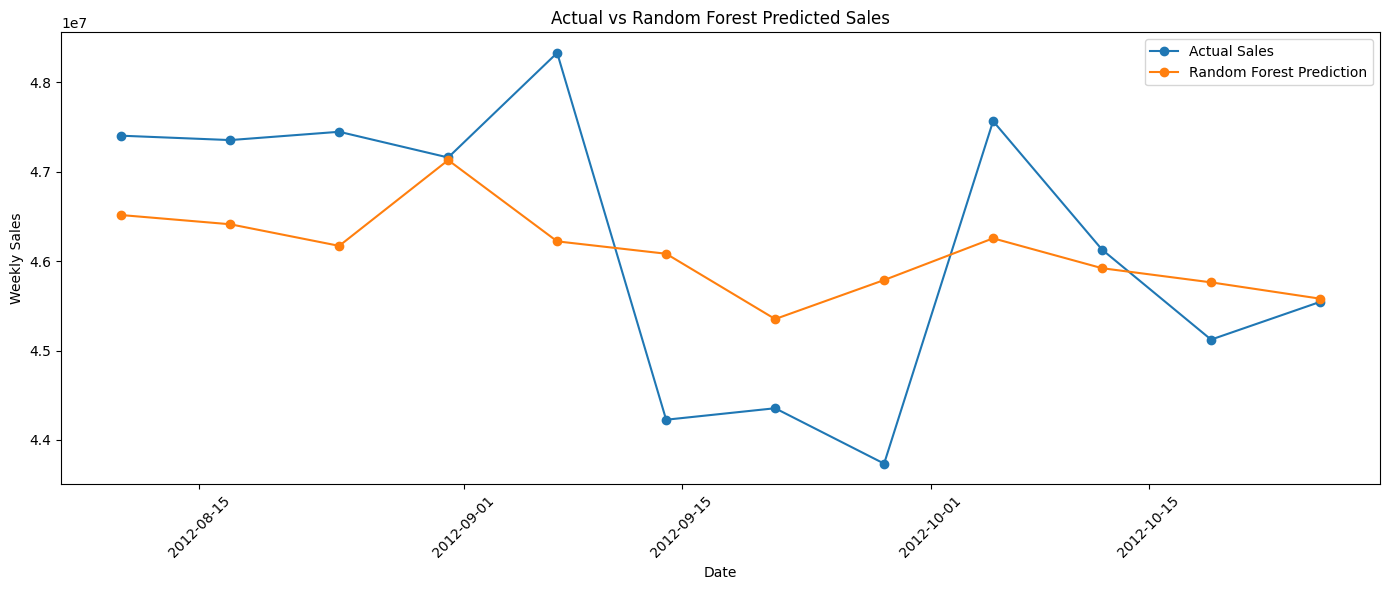

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(
    comparison['Date'],
    comparison['Actual_Sales'],
    marker='o',
    label='Actual Sales'
)

plt.plot(
    comparison['Date'],
    comparison['Random_Forest'],
    marker='o',
    label='Random Forest Prediction'
)

plt.title('Actual vs Random Forest Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.savefig(
    "../outputs/charts/10_actual_vs_forecast.png",
    dpi=300,
    bbox_inches='tight'
)


plt.show()

In [34]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(
    'Importance',
    ascending=False
)

feature_importance

,Feature,Importance
11,Week,0.498460
0,Lag_1,0.177083
2,Lag_4,0.102350
3,Lag_8,0.066331
4,Lag_12,0.040427
1,Lag_2,0.037072
6,Rolling_8,0.026215
9,Month,0.016309
7,Rolling_12,0.015321
5,Rolling_4,0.013832


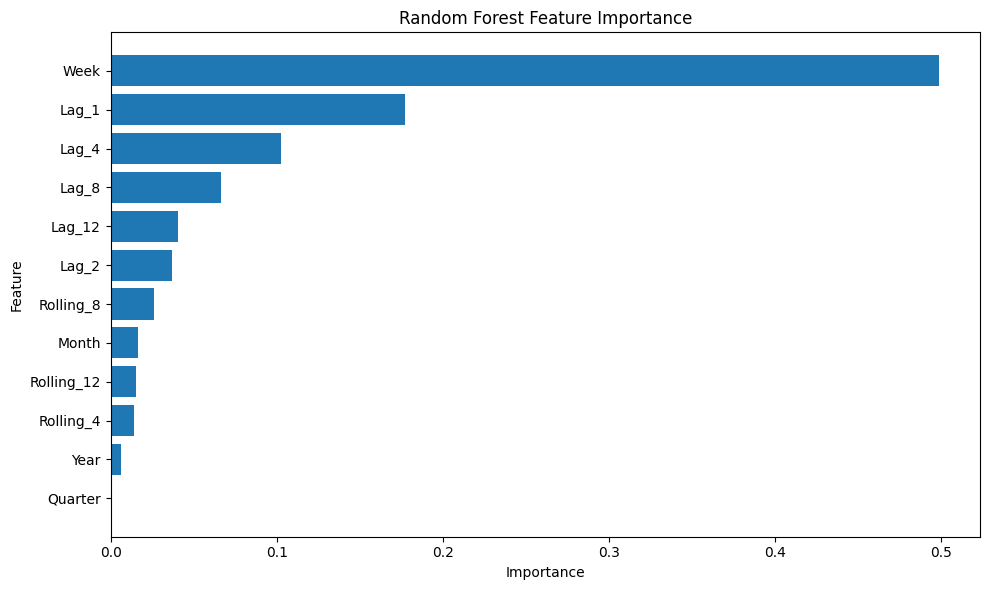

In [35]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.gca().invert_yaxis()

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.savefig(
    "../outputs/charts/11_feature_importance.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [36]:
model_results

,Model,MAE,RMSE,MAPE (%)
0,Baseline,1.102690e+06,1.747723e+06,2.401659
1,Linear Regression,2.150262e+06,2.725167e+06,4.769562
2,Random Forest,1.028920e+06,1.244496e+06,2.235404


In [37]:
feature_importance

,Feature,Importance
11,Week,0.498460
0,Lag_1,0.177083
2,Lag_4,0.102350
3,Lag_8,0.066331
4,Lag_12,0.040427
1,Lag_2,0.037072
6,Rolling_8,0.026215
9,Month,0.016309
7,Rolling_12,0.015321
5,Rolling_4,0.013832


In [38]:
print("Last historical date:")
print(weekly_sales['Date'].max())

Last historical date:
2012-10-26 00:00:00


In [39]:
future_steps = 12

history = weekly_sales.copy()

future_predictions = []

for i in range(future_steps):

    last_date = history['Date'].iloc[-1]

    next_date = last_date + pd.Timedelta(days=7)

    lag_1 = history['Sales'].iloc[-1]
    lag_2 = history['Sales'].iloc[-2]
    lag_4 = history['Sales'].iloc[-4]
    lag_8 = history['Sales'].iloc[-8]
    lag_12 = history['Sales'].iloc[-12]

    rolling_4 = history['Sales'].iloc[-4:].mean()
    rolling_8 = history['Sales'].iloc[-8:].mean()
    rolling_12 = history['Sales'].iloc[-12:].mean()

    year = next_date.year
    month = next_date.month
    quarter = next_date.quarter
    week = next_date.isocalendar().week

    future_row = pd.DataFrame({
        'Lag_1': [lag_1],
        'Lag_2': [lag_2],
        'Lag_4': [lag_4],
        'Lag_8': [lag_8],
        'Lag_12': [lag_12],
        'Rolling_4': [rolling_4],
        'Rolling_8': [rolling_8],
        'Rolling_12': [rolling_12],
        'Year': [year],
        'Month': [month],
        'Quarter': [quarter],
        'Week': [int(week)]
    })

    prediction = rf_model.predict(future_row)[0]

    future_predictions.append({
        'Date': next_date,
        'Forecasted_Sales': prediction
    })

    # Add prediction to history so the next iteration
    # can use it as a lag value
    new_row = pd.DataFrame({
        'Date': [next_date],
        'Sales': [prediction]
    })

    history = pd.concat(
        [history, new_row],
        ignore_index=True
    )

In [40]:
future_forecast = pd.DataFrame(future_predictions)

future_forecast

,Date,Forecasted_Sales
0,2012-11-02,4.582505e+07
1,2012-11-09,4.621535e+07
2,2012-11-16,4.675878e+07
3,2012-11-23,6.078655e+07
4,2012-11-30,5.612309e+07
5,2012-12-07,5.720825e+07
6,2012-12-14,6.067095e+07
7,2012-12-21,6.570528e+07
8,2012-12-28,5.015114e+07
9,2013-01-04,4.527926e+07


In [41]:
future_forecast['Forecasted_Sales'] = (
    future_forecast['Forecasted_Sales'].round(2)
)

future_forecast

,Date,Forecasted_Sales
0,2012-11-02,45825048.32
1,2012-11-09,46215350.82
2,2012-11-16,46758780.12
3,2012-11-23,60786553.30
4,2012-11-30,56123088.50
5,2012-12-07,57208253.37
6,2012-12-14,60670949.05
7,2012-12-21,65705278.54
8,2012-12-28,50151136.99
9,2013-01-04,45279258.29


In [42]:
future_forecast.to_csv(
    "../outputs/future_sales_forecast.csv",
    index=False
)

print("✅ Forecast saved successfully!")

✅ Forecast saved successfully!


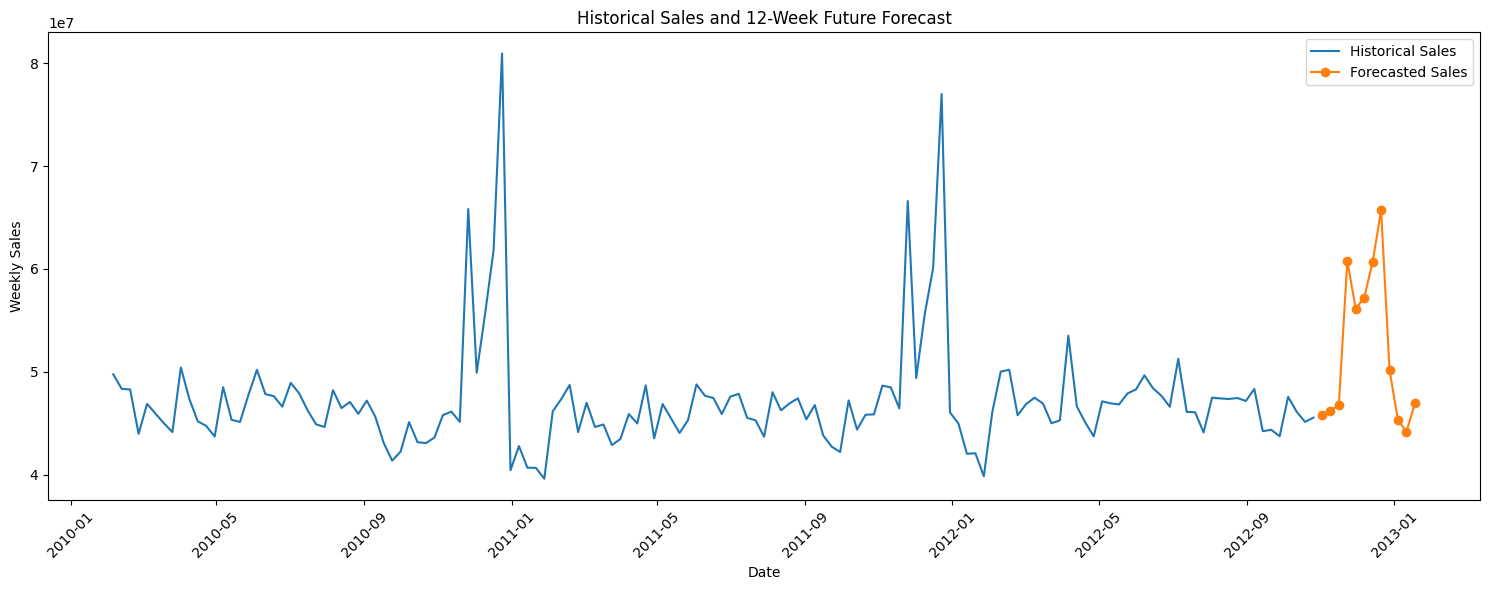

In [45]:
plt.figure(figsize=(15, 6))

plt.plot(
    weekly_sales['Date'],
    weekly_sales['Sales'],
    label='Historical Sales'
)

plt.plot(
    future_forecast['Date'],
    future_forecast['Forecasted_Sales'],
    marker='o',
    label='Forecasted Sales'
)

plt.title('Historical Sales and 12-Week Future Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()

plt.savefig(
    "../outputs/charts/12_future_sales_forecast.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [44]:
total_forecast = future_forecast['Forecasted_Sales'].sum()

average_forecast = future_forecast['Forecasted_Sales'].mean()

highest_forecast = future_forecast.loc[
    future_forecast['Forecasted_Sales'].idxmax()
]

lowest_forecast = future_forecast.loc[
    future_forecast['Forecasted_Sales'].idxmin()
]

print(f"12-Week Forecast Total: ${total_forecast:,.2f}")
print(f"Average Forecasted Weekly Sales: ${average_forecast:,.2f}")

print("\nHighest Forecast:")
print(highest_forecast)

print("\nLowest Forecast:")
print(lowest_forecast)

12-Week Forecast Total: $625,817,666.20
Average Forecasted Weekly Sales: $52,151,472.18

Highest Forecast:
Date                2012-12-21 00:00:00
Forecasted_Sales            65705278.54
Name: 7, dtype: object

Lowest Forecast:
Date                2013-01-11 00:00:00
Forecasted_Sales             44173879.8
Name: 10, dtype: object
